# Dipole near a nanosphere

Read the Purcell factor, the quenching and the directivity of a dipole emitting near a nanosphere.

**Question.** An emitter, a molecule or a quantum dot, radiates at a vacuum
wavelength of 1 µm in air, a few tens of nanometres from a sphere of radius
150 nm. The sphere is silicon or gold. How much faster does the emitter
radiate than in air (its {term}`Purcell factor`), how much of that power
leaves as light rather than heating the sphere (its {term}`radiative
efficiency`), and in which directions does the light go?

The emitter is a {py:obj}`gfem.ElectricDipole`, a {term}`source` of a driven
problem, and the answers are three outputs of one solve:
{py:func}`gfem.purcell_factor`, {py:func}`gfem.power_flow` and
{py:func}`gfem.far_field`. A dipole is a column of the solve: every position
and orientation shares one factorization per sphere. A dipole outside a
sphere has a closed form, a multipole series, and the page checks every
Purcell factor and efficiency against it.

**Assumptions.**

- The host is air, lossless: a dipole must sit in a lossless material (gfem
  refuses one in a lossy region, where its emitted power has no limit).
- Silicon has a constant, lossless index of 3.5. Gold follows a Drude
  law (plasma frequency 9.03 eV, damping 0.053 eV): at 1 µm,
  $\varepsilon \approx -52 - 2.3i$. Measured gold differs by some percent
  there; the law is a model, not data.
- The dipoles sit on one axis through the sphere's centre, oriented along it
  (radial) or across it (tangential).
- A {term}`perfectly matched layer` closes the air box, so the emitted light
  leaves the model.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.constants import c
from scipy.special import spherical_jn, spherical_yn

import gfem

um, nm = 1e-6, 1e-9
WAVELENGTH = 1.0 * um
F0 = c / WAVELENGTH  # 299.8 THz
K0 = 2 * np.pi / WAVELENGTH
RADIUS = 0.15 * um  # the sphere's nominal radius

## The sphere and its mesh

The mesh is a sphere, region `"sphere"`, in a cube of air, region `"air"`,
0.9 µm across, wrapped in a 0.35 µm layer, region `"pml"`. It is built by
`tools/nanosphere_mesh.py` (netgen) and read from
{download}`data/nanosphere.msh`. Its elements are straight tetrahedra, at
most 0.3 µm in the air, 0.08 µm inside the sphere and 0.045 µm along its
surface. The emitters sit on the $+z$ axis, so a box around that axis,
from 25 nm inside the sphere to 45 nm outside it, is meshed at 18 nm:
near a metal a dipole's field varies on the scale of its distance.

Straight tetrahedra cut the sphere's surface, so the meshed sphere is
slightly smaller than the round one. The closed form below is evaluated at
the radius of a round sphere of the same volume, $a_\mathrm{vol}$.

In [2]:
mesh = gfem.Mesh.from_gmsh("data/nanosphere.msh", length_unit="um")
corners = np.asarray(mesh.nodes)[mesh.tetrahedra[mesh.elements("sphere")]]
edges = corners[:, 1:] - corners[:, :1]
volume = abs(np.linalg.det(edges)).sum() / 6
a_vol = (3 * volume / (4 * np.pi)) ** (1 / 3)
print(f"{len(mesh.tetrahedra)} tetrahedra")
print(f"a_vol = {a_vol / nm:.1f} nm (nominal {RADIUS / nm:.0f} nm)")

AIR = gfem.Material(name="air")
SILICON = gfem.Material(eps_r=3.5**2, name="silicon")
GOLD = gfem.Material(
    eps_r=gfem.PermittivityLaw(
        eps_inf=1.0,
        terms=[gfem.Drude(plasma_frequency=2.183e15, damping=1.28e13)],
    ),
    name="gold",
)
eps_gold = complex(GOLD.eps_r(F0))
print(f"gold at 1 um: eps = {eps_gold:.2f}")

8015 tetrahedra
a_vol = 148.4 nm (nominal 150 nm)


gold at 1 um: eps = -51.93-2.26j


## Dipoles beside the sphere

Five distances $d$ from the sphere's surface, from 30 to 150 nm, two
orientations each: ten dipoles, all of moment $10^{-30}$ C·m. One driven
problem holds them all as sources, `excite=()` because the model has no
port; the solve factors the matrix once and back-substitutes ten columns.

Three models share the mesh: the sphere made of air (the dipole alone, a
check), of silicon and of gold. `background=air` names the
{term}`exterior medium` the far field is read in.

In [3]:
DISTANCES = np.array([30, 45, 70, 100, 150]) * nm
AXES = {"radial": (0, 0, 1), "tangential": (1, 0, 0)}
MOMENT = 1e-30  # C m
dipoles = [
    gfem.ElectricDipole(
        f"{axis} {k}",
        position=(0, 0, RADIUS + d),
        moment=MOMENT * np.array(direction),
    )
    for k, d in enumerate(DISTANCES)
    for axis, direction in AXES.items()
]
problem = gfem.Driven(F0, excite=(), sources=dipoles, keep_fields=True)
options = gfem.SolverOptions(order=3)

models, results = {}, {}
for name, material in (("air", AIR), ("silicon", SILICON), ("gold", GOLD)):
    models[name] = gfem.Model(
        mesh,
        materials={"sphere": material, "air": AIR, "pml": AIR},
        pml=gfem.PML("pml"),
        background=AIR,
    )
    results[name] = gfem.solve(models[name], problem, options=options)


def purcell(name, axis):
    # Purcell factor of each distance's dipole along `axis` (array over DISTANCES)
    return np.array(
        [
            float(
                gfem.purcell_factor(results[name], f"{axis} {k}", model=models[name])[0]
            )
            for k in range(len(DISTANCES))
        ]
    )


F = {(name, axis): purcell(name, axis) for name in results for axis in AXES}
print("d (nm)       " + "  ".join(f"{d / nm:6.0f}" for d in DISTANCES))
for (name, axis), values in F.items():
    print(f"{name:7s} {axis[:4]}  " + "  ".join(f"{v:6.3f}" for v in values))

d (nm)           30      45      70     100     150
air     radi   1.003   1.004   1.005   1.006   1.008
air     tang   0.998   0.997   0.997   0.995   0.993
silicon radi   6.884   5.151   3.451   2.363   1.524
silicon tang   0.483   0.373   0.298   0.300   0.418
gold    radi   7.357   5.424   3.591   2.433   1.550
gold    tang   0.196   0.247   0.369   0.504   0.697


**The dipole alone.** With the sphere made of air the model is a dipole in
an unbounded medium, and its Purcell factor is 1: the
{term}`emitted power` $P$ equals the {term}`bulk power` $P_0$ that
`purcell_factor` divides by. The ten columns read 1.0 within 1 %, the
discretization error of the emitted power on this mesh.

**Silicon.** A radial dipole emits faster close to the sphere, 6.9 times
faster at 30 nm. A tangential one is slowed down at every distance, to
between 0.30 and 0.48 of its power in air: the field the sphere sends back
to it is out of phase with its own.

**Gold.** A radial dipole is sped up more, 7.4 times at 30 nm: the metal
holds the dipole's image, parallel to it. A tangential dipole's image
points against it, and the two nearly cancel: at 30 nm it emits a fifth of
its power in air. Closer to the metal its emitted power rises again (the
series below: 0.89 at 10 nm), as its near field heats the gold.

## Where the power goes

The emitted power leaves in two ways: into the layer (the light that
reaches the far field) and into the sphere (heat in the gold).
`power_flow` gives both, as the power entering the `"pml"` and the
`"sphere"` regions. The {term}`radiative efficiency` is the share that
leaves as light, $\eta = P_\text{rad} / P$. The two powers add up to the
emitted power, which is a check of the solve: the residual form behind
`power_flow` makes the balance hold to the solver's round-off.

In [4]:
def split(name, axis, k):
    # (P_rad / P, (P_rad + P_abs) / P) of one dipole
    source = f"{axis} {k}"
    field = results[name].e_field(F0, source)
    emitted = float(results[name].emitted_power[source][0])
    radiated = -float(gfem.power_flow(field, "pml", model=models[name]))
    absorbed = -float(gfem.power_flow(field, "sphere", model=models[name]))
    return radiated / emitted, (radiated + absorbed) / emitted


eta, balance = {}, 0.0
for name in ("silicon", "gold"):
    for axis in AXES:
        pairs = np.array([split(name, axis, k) for k in range(len(DISTANCES))])
        eta[name, axis] = pairs[:, 0]
        balance = max(balance, float(np.abs(pairs[:, 1] - 1).max()))
print("radiative efficiency")
print("d (nm)       " + "  ".join(f"{d / nm:6.0f}" for d in DISTANCES))
for (name, axis), values in eta.items():
    print(f"{name:7s} {axis[:4]}  " + "  ".join(f"{v:6.3f}" for v in values))
print(f"largest |(P_rad + P_abs) / P - 1| = {balance:.1e}")

radiative efficiency
d (nm)           30      45      70     100     150
silicon radi   1.000   1.000   1.000   1.000   1.000
silicon tang   1.000   1.000   1.000   1.000   1.000
gold    radi   0.979   0.988   0.993   0.995   0.997
gold    tang   0.707   0.910   0.975   0.989   0.995
largest |(P_rad + P_abs) / P - 1| = 5.5e-13


Silicon is lossless: every photon leaves, $\eta = 1$. Near gold the
tangential dipole loses 29 % of its power to heat at 30 nm,
$\eta = 0.71$, against 0.995 at 150 nm: **quenching**. The radial dipole
keeps $\eta$ above 0.97 at these distances: its enhanced radiation
outgrows the heat. Closer still, both fall towards 0: by the series below,
the tangential dipole's $\eta$ is 0.07 at 10 nm. The radiated and absorbed
powers add up to the emitted power to $10^{-12}$.

## The closed form: a dipole outside a sphere

A dipole outside a sphere has an exact solution as a series of vector
spherical harmonics (Chew 1987; Kim, Leung and George 1988). With $x = ka$
the sphere's size parameter, $y = kr_0$ with $r_0$ the dipole's distance
from the centre, $a_n$ and $b_n$ the sphere's Mie coefficients,
$h_n = j_n + i y_n$ and $\xi_n(y) = y h_n(y)$, $\psi_n(y) = y j_n(y)$,

$$
F_\perp = 1 + \frac{3}{2}\operatorname{Re}\sum_{n\ge1} n(n+1)(2n+1)\,
\tilde a_n \left(\frac{h_n(y)}{y}\right)^2, \qquad
F_\parallel = 1 + \frac{3}{4}\operatorname{Re}\sum_{n\ge1} (2n+1)
\left[\tilde b_n h_n(y)^2 + \tilde a_n \left(\frac{\xi_n'(y)}{y}\right)^2\right],
$$

$$
\eta_\perp F_\perp = \frac{3}{2}\sum_{n\ge1} n(n+1)(2n+1)
\left|\frac{j_n(y) + \tilde a_n h_n(y)}{y}\right|^2, \qquad
\eta_\parallel F_\parallel = \frac{3}{4}\sum_{n\ge1} (2n+1)\left[
\left|j_n(y) + \tilde b_n h_n(y)\right|^2
+ \left|\frac{\psi_n'(y) + \tilde a_n \xi_n'(y)}{y}\right|^2\right],
$$

with $\tilde a_n = -a_n$, $\tilde b_n = -b_n$ in Bohren and Huffman's sign
for $a_n$, $b_n$. Their series is written for $e^{-i\omega t}$, so the
sphere's index is $m = \sqrt{\overline{\varepsilon}}$ for gfem's
$\varepsilon = \varepsilon' - i\varepsilon''$ under $e^{+i\omega t}$. For
a lossless sphere the two kinds of sum agree, $\eta = 1$, which fixes the
signs.

In [5]:
def series(eps, ka, kr, terms=60):
    # Purcell factors and radiative efficiencies of a radial and a tangential
    # dipole at kr outside a sphere of size ka: (F_perp, eta_perp, F_par, eta_par)
    n = np.arange(1, terms + 1)
    m = np.sqrt(np.conj(eps))

    def h(z, derivative=False):
        return spherical_jn(n, z, derivative) + 1j * spherical_yn(n, z, derivative)

    def psi(z):
        return z * spherical_jn(n, z)

    def dpsi(z):
        return spherical_jn(n, z) + z * spherical_jn(n, z, True)

    xi, dxi = ka * h(ka), h(ka) + ka * h(ka, True)
    a = (m * psi(m * ka) * dpsi(ka) - psi(ka) * dpsi(m * ka)) / (
        m * psi(m * ka) * dxi - xi * dpsi(m * ka)
    )
    b = (psi(m * ka) * dpsi(ka) - m * psi(ka) * dpsi(m * ka)) / (
        psi(m * ka) * dxi - m * xi * dpsi(m * ka)
    )
    a, b = -a, -b
    j, hy = spherical_jn(n, kr), h(kr)
    dxi_y, dpsi_y = hy + kr * h(kr, True), dpsi(kr)
    w_perp, w_par = 1.5 * n * (n + 1) * (2 * n + 1), 0.75 * (2 * n + 1)
    f_perp = 1 + np.sum(w_perp * a * (hy / kr) ** 2).real
    f_par = 1 + np.sum(w_par * (b * hy**2 + a * (dxi_y / kr) ** 2)).real
    r_perp = np.sum(w_perp * abs((j + a * hy) / kr) ** 2)
    r_par = np.sum(w_par * (abs(j + b * hy) ** 2 + abs((dpsi_y + a * dxi_y) / kr) ** 2))
    return f_perp, r_perp / f_perp, f_par, r_par / f_par


EPS = {"silicon": 3.5**2, "gold": eps_gold}


def closed_form(name, distances):
    # {(name, axis): (F, eta)} over `distances` from the meshed sphere's surface
    rows = np.array(
        [series(EPS[name], K0 * a_vol, K0 * (RADIUS + d)) for d in distances]
    )
    return {
        (name, "radial"): (rows[:, 0], rows[:, 1]),
        (name, "tangential"): (rows[:, 2], rows[:, 3]),
    }


reference = closed_form("silicon", DISTANCES) | closed_form("gold", DISTANCES)
series_error, efficiency_error = 0.0, 0.0
print("Purcell factor: gfem / series - 1 (%), and radiative efficiency")
print("d (nm)       " + "  ".join(f"{d / nm:6.0f}" for d in DISTANCES))
for key, (f_ref, eta_ref) in reference.items():
    error = F[key] / f_ref - 1
    series_error = max(series_error, float(np.abs(error).max()))
    efficiency_error = max(efficiency_error, float(np.abs(eta[key] - eta_ref).max()))
    name, axis = key
    print(f"{name:7s} {axis[:4]}  " + "  ".join(f"{100 * e:+6.2f}" for e in error))
    print("   eta series  " + "  ".join(f"{v:6.3f}" for v in eta_ref))
print(f"largest Purcell error {100 * series_error:.1f} %")
print(f"largest efficiency difference {efficiency_error:.3f}")

Purcell factor: gfem / series - 1 (%), and radiative efficiency
d (nm)           30      45      70     100     150
silicon radi   +2.98   +2.54   +2.19   +1.65   +1.32
   eta series   1.000   1.000   1.000   1.000   1.000
silicon tang   -0.04   -0.63   -1.17   -1.44   -1.38
   eta series   1.000   1.000   1.000   1.000   1.000
gold    radi   +3.62   +3.00   +2.56   +1.91   +1.45
   eta series   0.980   0.989   0.993   0.995   0.997
gold    tang   -0.52   -2.02   -1.48   -1.15   -1.00
   eta series   0.734   0.916   0.976   0.989   0.995
largest Purcell error 3.6 %
largest efficiency difference 0.027


Every Purcell factor is within 3.6 % of the series and every efficiency
within 0.027 of it. The errors are the discretization's:

- The radial factors read 1.3-3.6 % high at every distance, mostly the
  faceted sphere's share. The meshed surface is finer under the dipoles than
  elsewhere, so it lies between the round spheres of radius $a_\mathrm{vol}$
  and 150 nm, and the radial series at 30 nm moves by 4 % between the two.
- The tangential dipole near gold is the hardest case: its emitted power is
  a fifth of the bulk power, much of it heat in a skin 22 nm deep, so the
  absolute error of the emitted power weighs five times more. Its
  efficiency at 30 nm, 0.707 against 0.734, is the furthest from the series.

Below 30 nm the 18 nm elements no longer resolve the field between the
dipole and the metal: on this mesh, at 20 nm, the tangential factor near
gold reads 18 % high. A closer emitter needs elements of about half its
distance in that box.

The figure shows the series as lines, from 20 to 150 nm, and gfem's values
as dots: the Purcell factor (top) and the radiative efficiency (bottom).

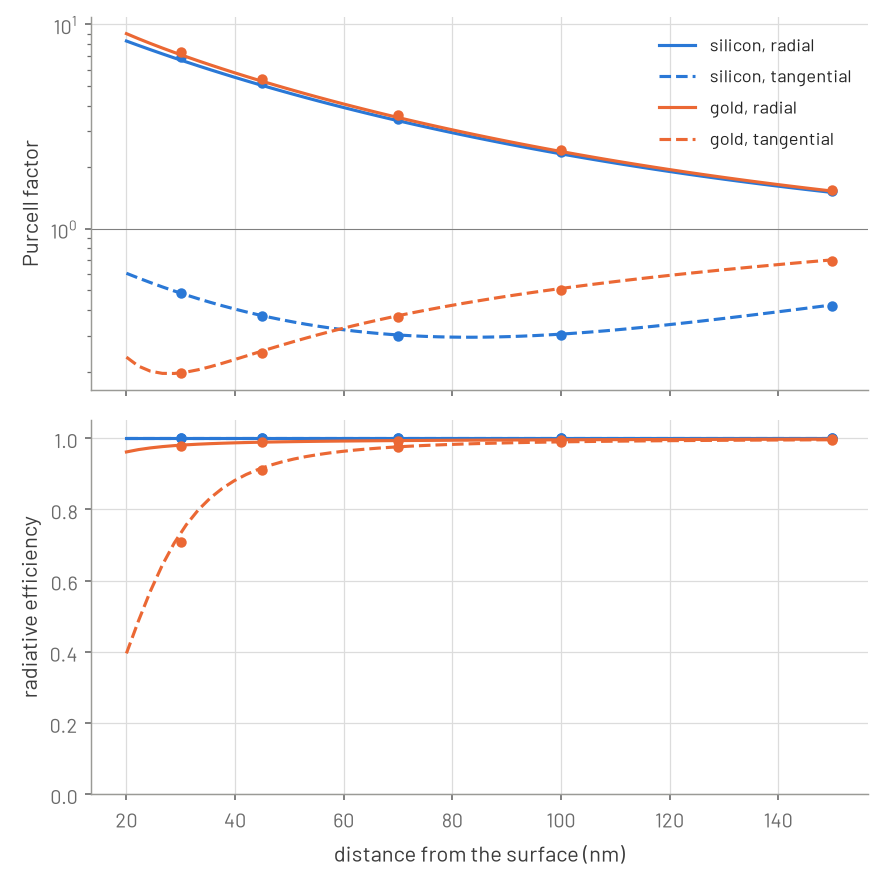

In [6]:
curve = np.linspace(20, 150, 60) * nm
lines = closed_form("silicon", curve) | closed_form("gold", curve)
fig, (top, bottom) = plt.subplots(2, 1, figsize=(6, 6), sharex=True)
styles = {"radial": "-", "tangential": "--"}
colors = {"silicon": "C0", "gold": "C1"}
for (name, axis), (f_ref, eta_ref) in lines.items():
    style = dict(color=colors[name], ls=styles[axis])
    top.plot(curve / nm, f_ref, **style, label=f"{name}, {axis}")
    bottom.plot(curve / nm, eta_ref, **style)
    top.plot(DISTANCES / nm, F[name, axis], "o", color=colors[name], ms=4)
    bottom.plot(DISTANCES / nm, eta[name, axis], "o", color=colors[name], ms=4)
top.axhline(1, color="gray", lw=0.5)
top.set_yscale("log")
top.set_ylabel("Purcell factor")
top.legend(fontsize="small")
bottom.set_ylim(0, 1.05)
bottom.set_xlabel("distance from the surface (nm)")
bottom.set_ylabel("radiative efficiency")
fig.tight_layout();

## Where the light goes

`gfem.far_field` reads each dipole's {term}`far-field amplitude` on the
air elements that touch the layer, and gives the {term}`radiation
intensity` $U$ and the {term}`directivity` $D = 4\pi U / P_\text{rad}$.
For the tangential dipole at 30 nm, over a Gauss-Legendre grid of the
sphere of directions, the integral of $U$ is a second check: it must equal
the radiated power that `far_field` takes from the residual, as
`power_flow` does.

A dipole in air radiates $D = 1.5$ broadside, and nothing along its axis.

In [7]:
x, w = np.polynomial.legendre.leggauss(24)
theta = np.arccos(x)[:, None]
phi = np.arange(48)[None, :] * np.pi / 24
weights = w[:, None] * np.full(48, np.pi / 24)[None, :]
SOURCE = "tangential 0"  # 30 nm from the surface

directivity, intensity_error = {}, 0.0
for name, result in results.items():
    far = gfem.far_field(result, SOURCE, theta, phi, model=models[name])
    radiated = float(far.radiated_power[0])
    total = float(np.sum(far.intensity[0] * weights))
    intensity_error = max(intensity_error, abs(total / radiated - 1))
    up, down = (
        float(gfem.far_field(result, SOURCE, t, 0.0, model=models[name]).directivity[0])
        for t in (0.0, np.pi)
    )
    directivity[name] = (float(far.directivity[0].max()), up, down)
    print(
        f"{name:7s}: integral of U / P_rad = {total / radiated:.4f}, "
        f"D max {directivity[name][0]:.3f}, D(+z) {up:.3f}, D(-z) {down:.3f}"
    )
bulk_directivity = directivity["air"][0]
front_back = directivity["silicon"][2] / directivity["silicon"][1]
print(f"silicon: D(-z) / D(+z) = {front_back:.2f}")

air    : integral of U / P_rad = 1.0021, D max 1.503, D(+z) 1.503, D(-z) 1.503


silicon: integral of U / P_rad = 1.0030, D max 2.456, D(+z) 0.301, D(-z) 1.554


gold   : integral of U / P_rad = 1.0049, D max 2.987, D(+z) 2.793, D(-z) 3.006
silicon: D(-z) / D(+z) = 5.16


The integrals of $U$ meet the radiated powers within 0.5 %, and the dipole
alone has its $D = 1.5$. Beside the silicon sphere the emission leans
through the sphere: the directivity along $-z$, the sphere's side, is 1.55,
5.2 times the 0.30 along $+z$, the dipole's own side. The strongest
emission, $D = 2.46$, goes along $\pm x$, the dipole's axis, where a dipole
alone sends nothing: there only the sphere's induced magnetic dipole, along
$y$, radiates. Along $z$ that magnetic dipole, the emitter and the sphere's
induced electric dipole all radiate: their fields add on the sphere's side
and partly cancel on the dipole's, as in Kerker's condition for a sphere
under a plane wave. Beside gold the emission is nearly the same along
$+z$ and $-z$, $D$ of 2.8 and 3.0.

The directivity in the $xz$ plane, the plane of the dipole and the axis,
for the dipole alone, beside silicon and beside gold. The dipole sits at the
top, on $+z$; the sphere is below it.

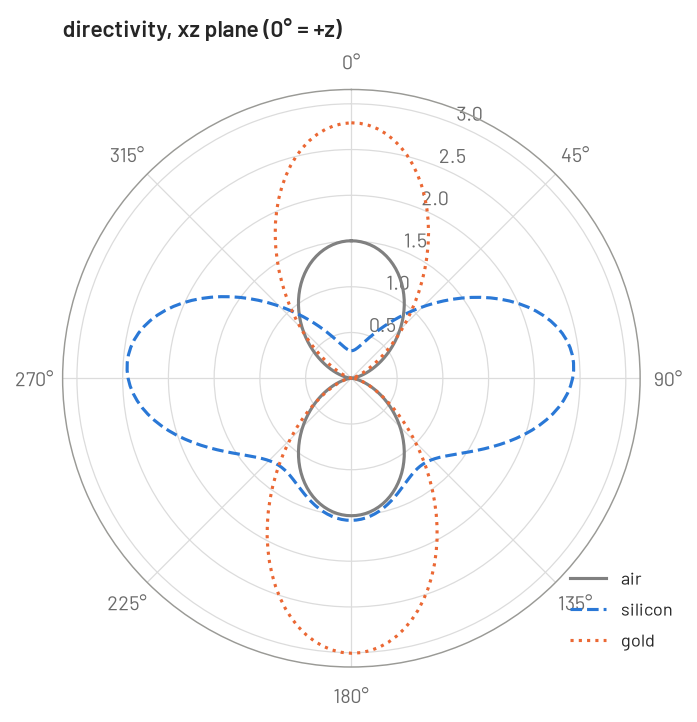

In [8]:
angles = np.linspace(0, 2 * np.pi, 181)
plane_theta = np.where(angles <= np.pi, angles, 2 * np.pi - angles)
plane_phi = np.where(angles <= np.pi, 0.0, np.pi)
fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(projection="polar")
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
for name, color in (("air", "gray"), ("silicon", "C0"), ("gold", "C1")):
    pattern = gfem.far_field(
        results[name], SOURCE, plane_theta, plane_phi, model=models[name]
    ).directivity[0]
    ax.plot(angles, np.asarray(pattern), color=color, label=name)
ax.set_title("directivity, xz plane (0° = +z)")
ax.legend(loc="lower left", bbox_to_anchor=(0.85, 0.0), fontsize="small");

## Limits

- **One wavelength.** The page solves at 1 µm only. A spectrum is one
  factorization per frequency: a {py:obj}`gfem.Driven` with several
  frequencies, or the adaptive sweep ({doc}`../recipes/frequency-sweep`),
  which takes dipoles.
- **Distances of 30 nm and more on this mesh.** Closer emitters need
  elements of about half their distance between the dipole and the metal;
  the refined box would have to grow finer. The emitted power converges with
  the whole domain's discretization (1-3 % at this size), not with the
  point source.
- **A faceted sphere.** Straight tetrahedra cut the surface. The page
  compares at the volume-equivalent radius; the radial factors keep a few
  percent of the faceting.
- **A Drude model of gold.** Interband absorption, which matters below
  about 600 nm, is left out; at 1 µm the model is within some percent of
  measured gold.
- **A dipole in a lossless host.** gfem refuses a dipole inside a lossy
  region, on an interface or in the layer
  ({doc}`../recipes/point-dipoles`).

## Next

- {doc}`../recipes/point-dipoles`: the emitted power, the beta factor of a
  guided mode and the best orientation from three columns.
- {doc}`../recipes/far-field`: patterns, gain, circular polarization and
  radar cross sections.
- {doc}`../recipes/cross-sections`: the same sphere lit by a plane wave,
  against Mie.
- {py:mod}`gfem.conventions`: point dipoles and far fields, their units and
  signs.

The numbers this page relies on, checked: the dipole alone (Purcell factor
1.0 and directivity 1.5), the Purcell factors and efficiencies against the
series (at three times the 3.6 % and 0.027 measured here), the power split,
the intensity integrated against the radiated power, and the silicon
sphere's front-to-back ratio, above 3.

In [9]:
bulk = np.concatenate([F["air", axis] for axis in AXES])
np.testing.assert_allclose(bulk, 1.0, atol=0.025)
np.testing.assert_allclose(bulk_directivity, 1.5, atol=0.01)
np.testing.assert_array_less(series_error, 0.11)
np.testing.assert_array_less(efficiency_error, 0.08)
np.testing.assert_array_less(balance, 1e-9)
np.testing.assert_array_less(intensity_error, 0.015)
np.testing.assert_array_less(3, front_back)